# 200 ms bilateral hip-angle forecast ensemble

Can disagreement predict unfamiliar motion while future encoder readings expose actual errors?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'forecast-angle'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/vanilla/runs/forecast_angle`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

Each branch predicts the two standardized hip encoder angles 40 raw samples ahead:
 $$y_t=[\theta_L(t+40),\theta_R(t+40)],\qquad 40/200=0.2\text{ s}.$$
 The trunk is unchanged, with two **linear** outputs. A target is valid only if its future
 row exists within the same trial; trial-end targets are masked, not filled with fake zeros.
 No future measurement enters the input. Prediction error becomes available only after 200 ms.

For branch $m$ and target dimension $d$, train with masked mean squared error:

$$\mathcal L=\frac{\sum_{n,m,d}a_{nd}(f_{md}(x_n)-y_{nd})^2}
{M\sum_{n,d}a_{nd}},\qquad M=7.$$

$a$ is the target-validity mask. The online score uses no target labels:

$$\bar f_d(x)=\frac1M\sum_m f_{md}(x),\qquad
\Psi(x)=\frac1D\sum_d\frac1M\sum_m(f_{md}(x)-\bar f_d(x))^2.$$

This is population variance across branches, not sample variance. Agreement is a candidate
uncertainty signal, **not a guarantee that an input is familiar or a prediction is correct**.

 **Krogh–Vedelsby is post-training analysis, not an extra training loss:**
 $$E=\|\bar f-y\|^2/D,\quad
 \overline E=\frac1M\sum_m\|f_m-y\|^2/D,\quad A=\Psi,\qquad E=\overline E-A.$$
 Compute this identity on the same raw predictions/valid targets; independent median filtering
 does not generally preserve the identity. High error with low disagreement is a confident failure.

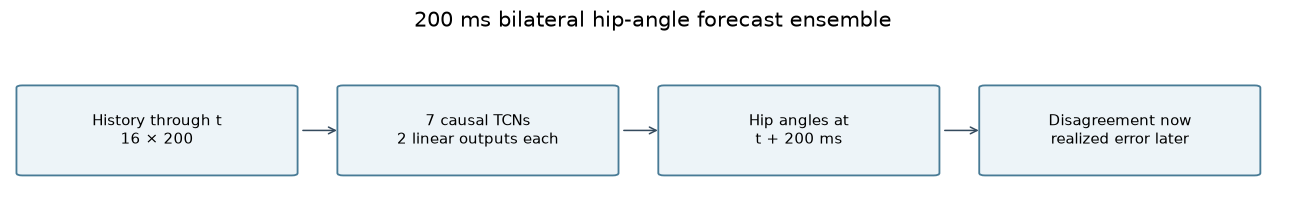

In [3]:
diagram([['History through t\n16 × 200', '7 causal TCNs\n2 linear outputs each', 'Hip angles at\nt + 200 ms', 'Disagreement now\nrealized error later']], '200 ms bilateral hip-angle forecast ensemble')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.ensemble import create_ensemble
model = create_ensemble(16, 2, activation='linear')
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

GaitPhaseEnsemble: 321,524 parameters
Input: (2, 16, 200)   Outputs: [(2, 7, 2)]
Layer table shows one representative branch; weights are not shared.


,module,class,direct parameters
0,network.0.conv,CausalConv1d,9630
1,network.0.norm,BatchNorm1d,60
2,network.0.relu,ReLU,0
3,network.1.conv,CausalConv1d,18030
4,network.1.norm,BatchNorm1d,60
5,network.1.relu,ReLU,0
6,network.2.conv,CausalConv1d,18030
7,network.2.norm,BatchNorm1d,60
8,network.2.relu,ReLU,0
9,fc,Linear,62


## Training


Twelve leave-one-subject-out (LOSO) folds over the training participants select the final
epoch count from held-out-subject loss. A freshly initialized ensemble then trains on all
training participants for that duration. Defaults: Adam, learning rate 0.001, batch 1024,
maximum 60 fold epochs, patience 10. The report below is authoritative for a saved run.
Branches have independent weights/initialization but see the same training batches.
 The regression target is future encoder angle; KV decomposition and OOD scoring are evaluated after training.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,ml/sci_rob/vanilla/runs/forecast_angle
loso_folds,None


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/Users/dariussattari/Documents/thesis/Uncertai...
loso_folds,None


,saved result
target,forecast_angle
horizon,40
threshold,0.010146
val_loss,0.041009
LOSO selected epochs,20


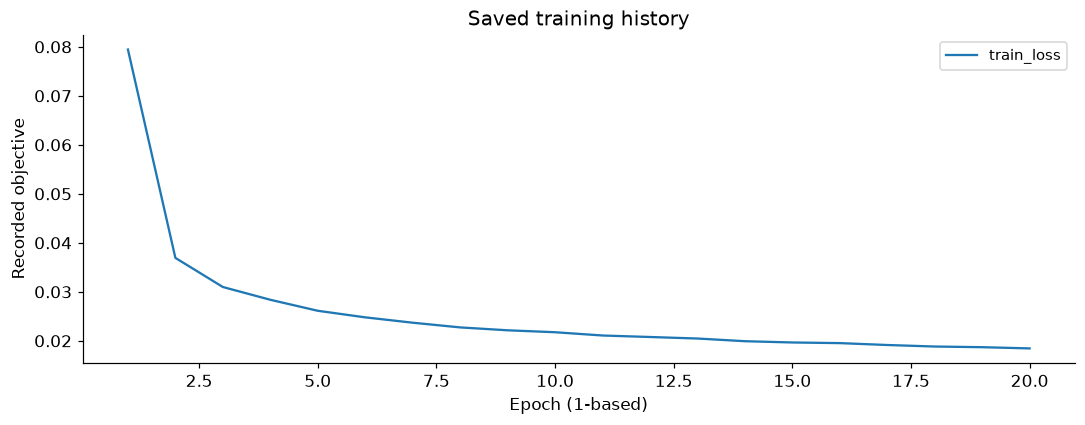

,epoch,train_loss,seconds
15,15,0.019517,119.6
16,16,0.019132,120.1
17,17,0.018821,119.9
18,18,0.018685,119.5
19,19,0.018437,119.9


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 20,
 'folds': [{'subject': 'AB15',
   'best_epoch': 16,
   'val_loss': 0.04183620243417581,
   'epochs_run': 27},
  {'subject': 'AB17',
   'best_epoch': 36,
   'val_loss': 0.031002520036888078,
   'epochs_run': 47},
  {'subject': 'AB18',
   'best_epoch': 27,
   'val_loss': 0.06826337822878871,
   'epochs_run': 38},
  {'subject': 'AB19',
   'best_epoch': 13,
   'val_loss': 0.04212190439469284,
   'epochs_run': 24},
  {'subject': 'AB21',
   'best_epoch': 17,
   'val_loss': 0.040528478755976136,
   'epochs_run': 28},
  {'subject': 'AB23',
   'best_epoch': 4,
   'val_loss': 0.03962630999666518,
   'epochs_run': 15},
  {'subject': 'AB25',
   'best_epoch': 16,
   'val_loss': 0.06195030214603799,
   'epochs_run': 27},
  {'subject': 'AB26',
   'best_epoch': 35,
   'val_loss': 0.02541939082247268,
   'epochs_run': 46},
  {'subject': 'AB27',
   'best_epoch': 27,
   'val_loss': 0.03681887421128386,
   'epochs_run': 38},
  {'subject': 'AB28',
   'best_epoch': 6,
   'val_loss': 0.06699

In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/vanilla/main.py all --model forecast-angle --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/forecast-angle

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.8964,52.0245,95.6146,0.4764,0.0101


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,5.2079,0.0046
1,RA,ID,18504,3.7181,0.0056
2,RD,ID,14784,3.6255,0.0052
3,SA,OOD,10273,37.8955,0.0092
4,SD,OOD,10155,62.6883,0.0119
5,ST,OOD,621,100.0000,0.0316
6,TR,OOD,1994,55.5667,0.0128


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**psi_by_task.png** — Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.

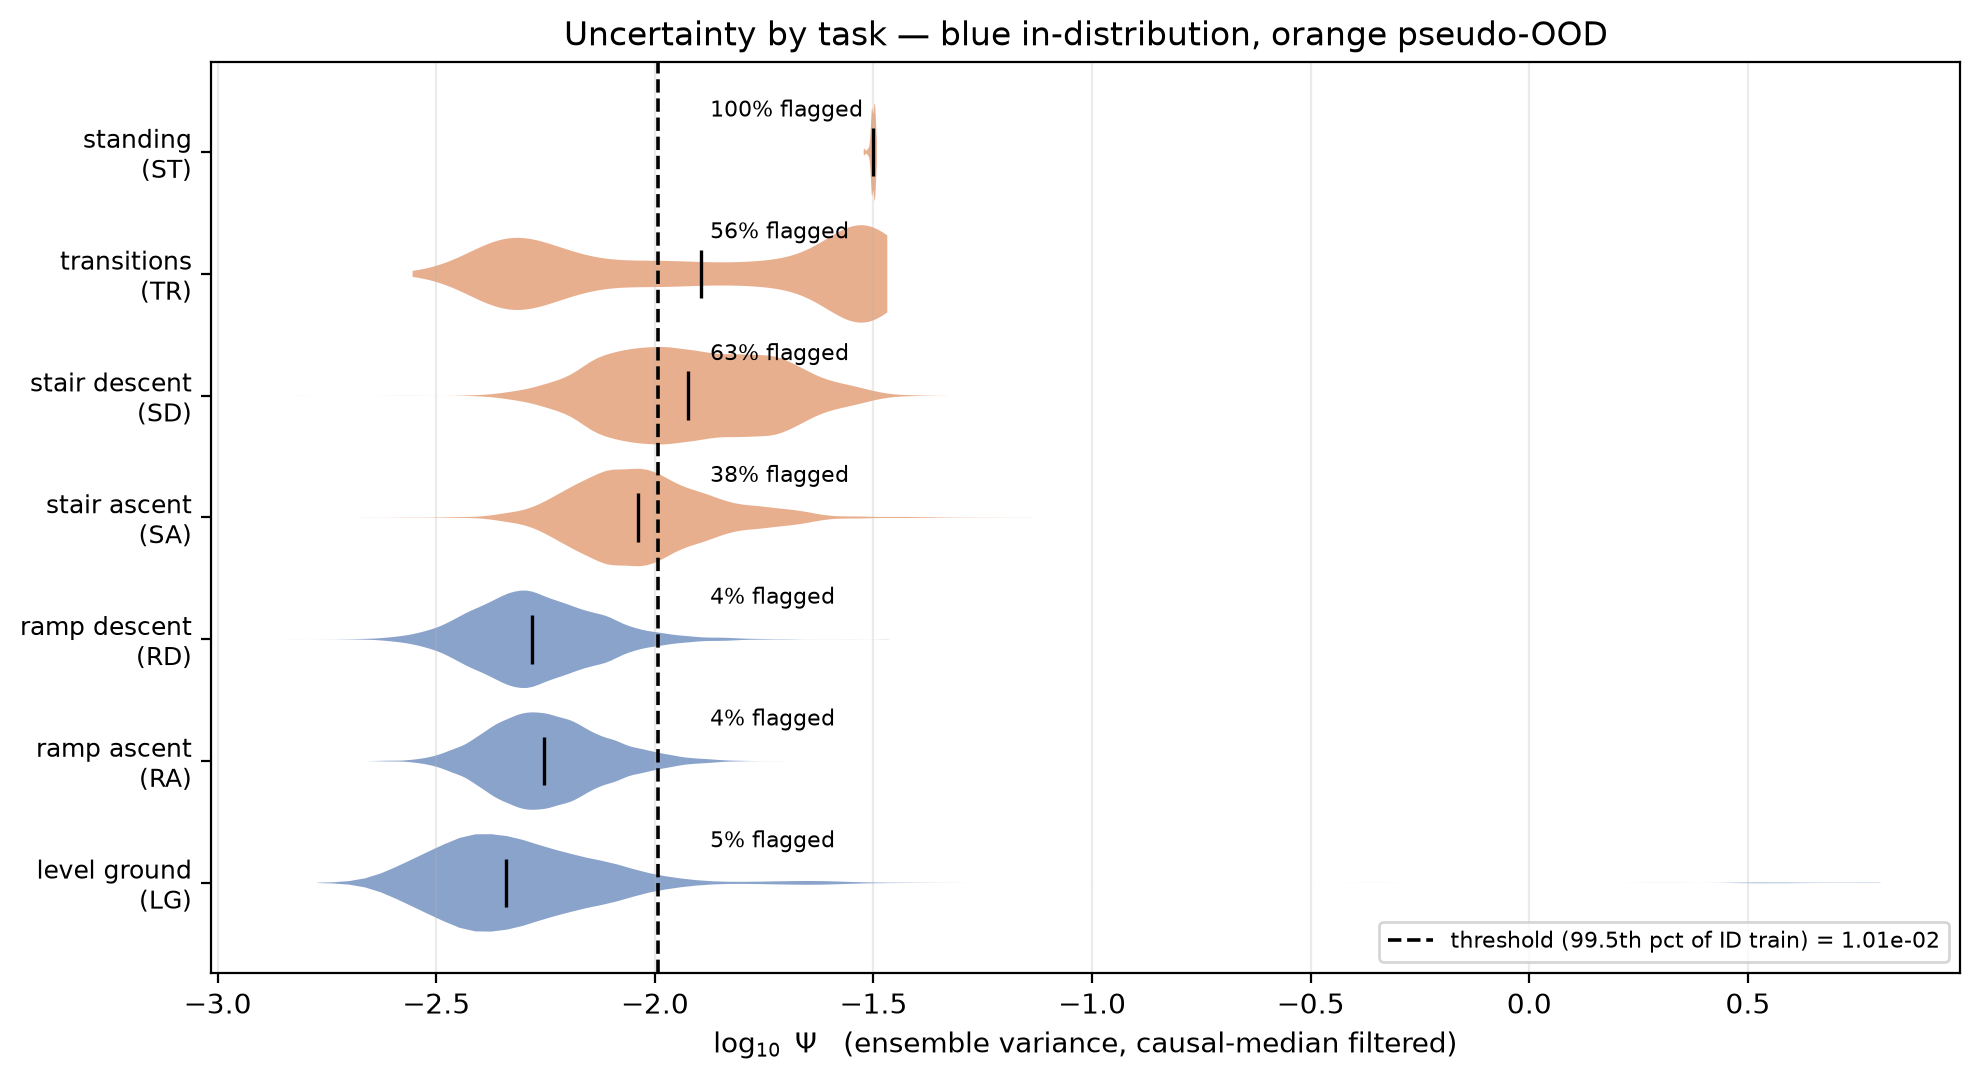

**roc.png** — Threshold sweep: ranking quality, not the fraction detected at the saved threshold.

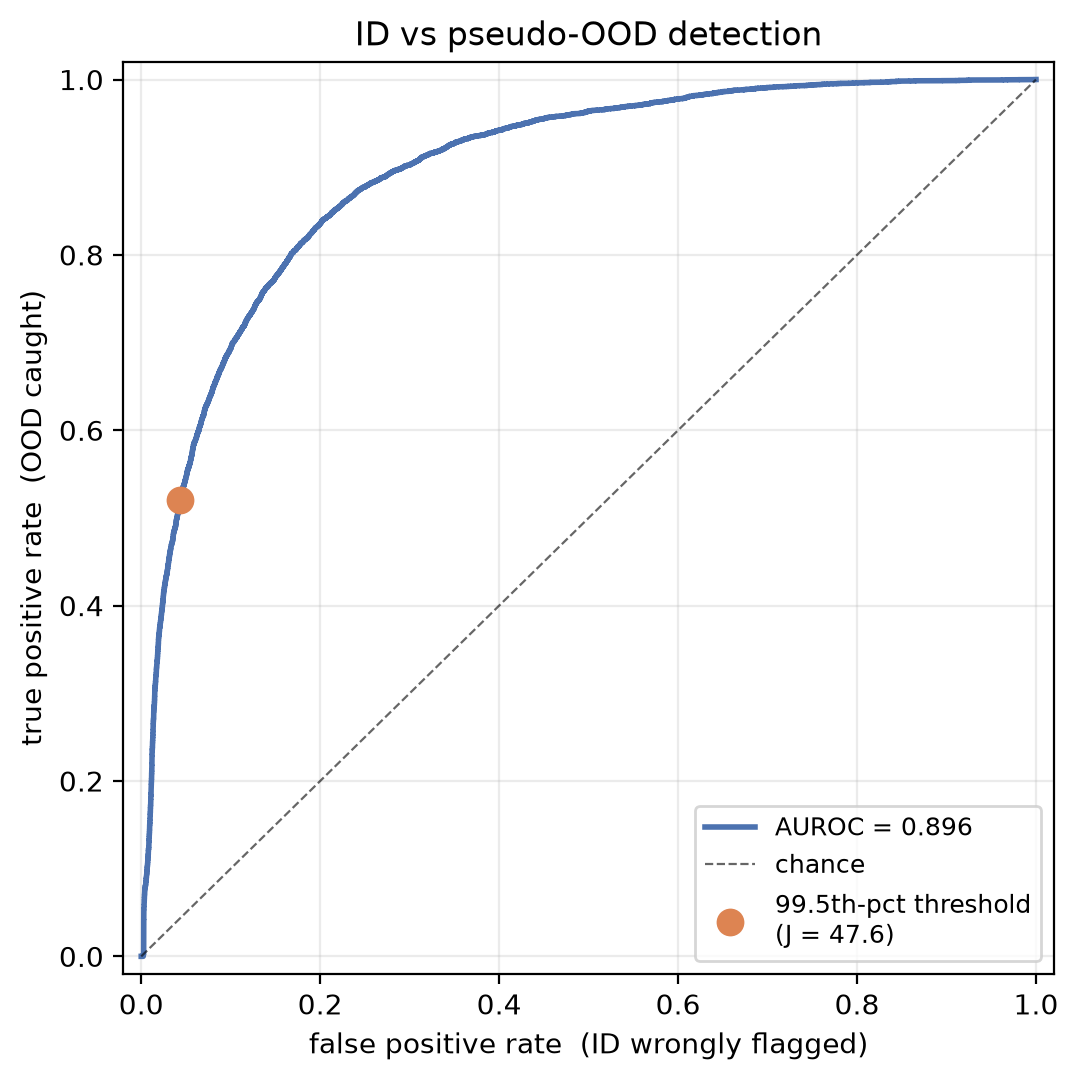

**detection_by_task.png** — Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.

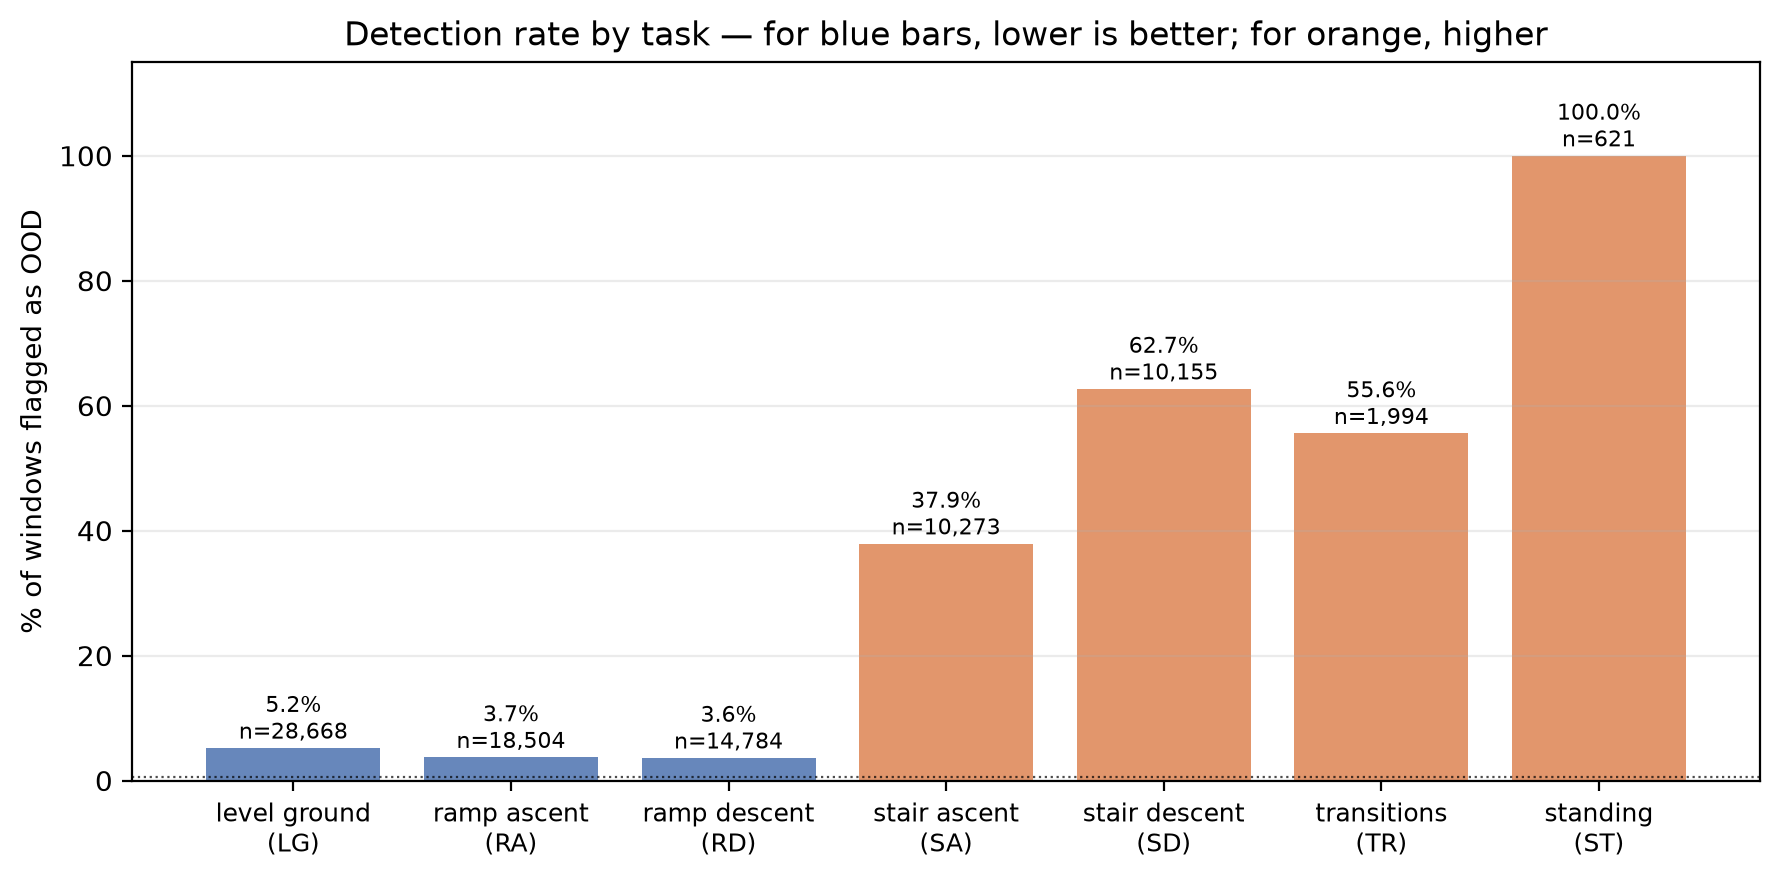

**kv_identity.png** — Numerical check of E = mean branch error − disagreement, on compatible unfiltered quantities.

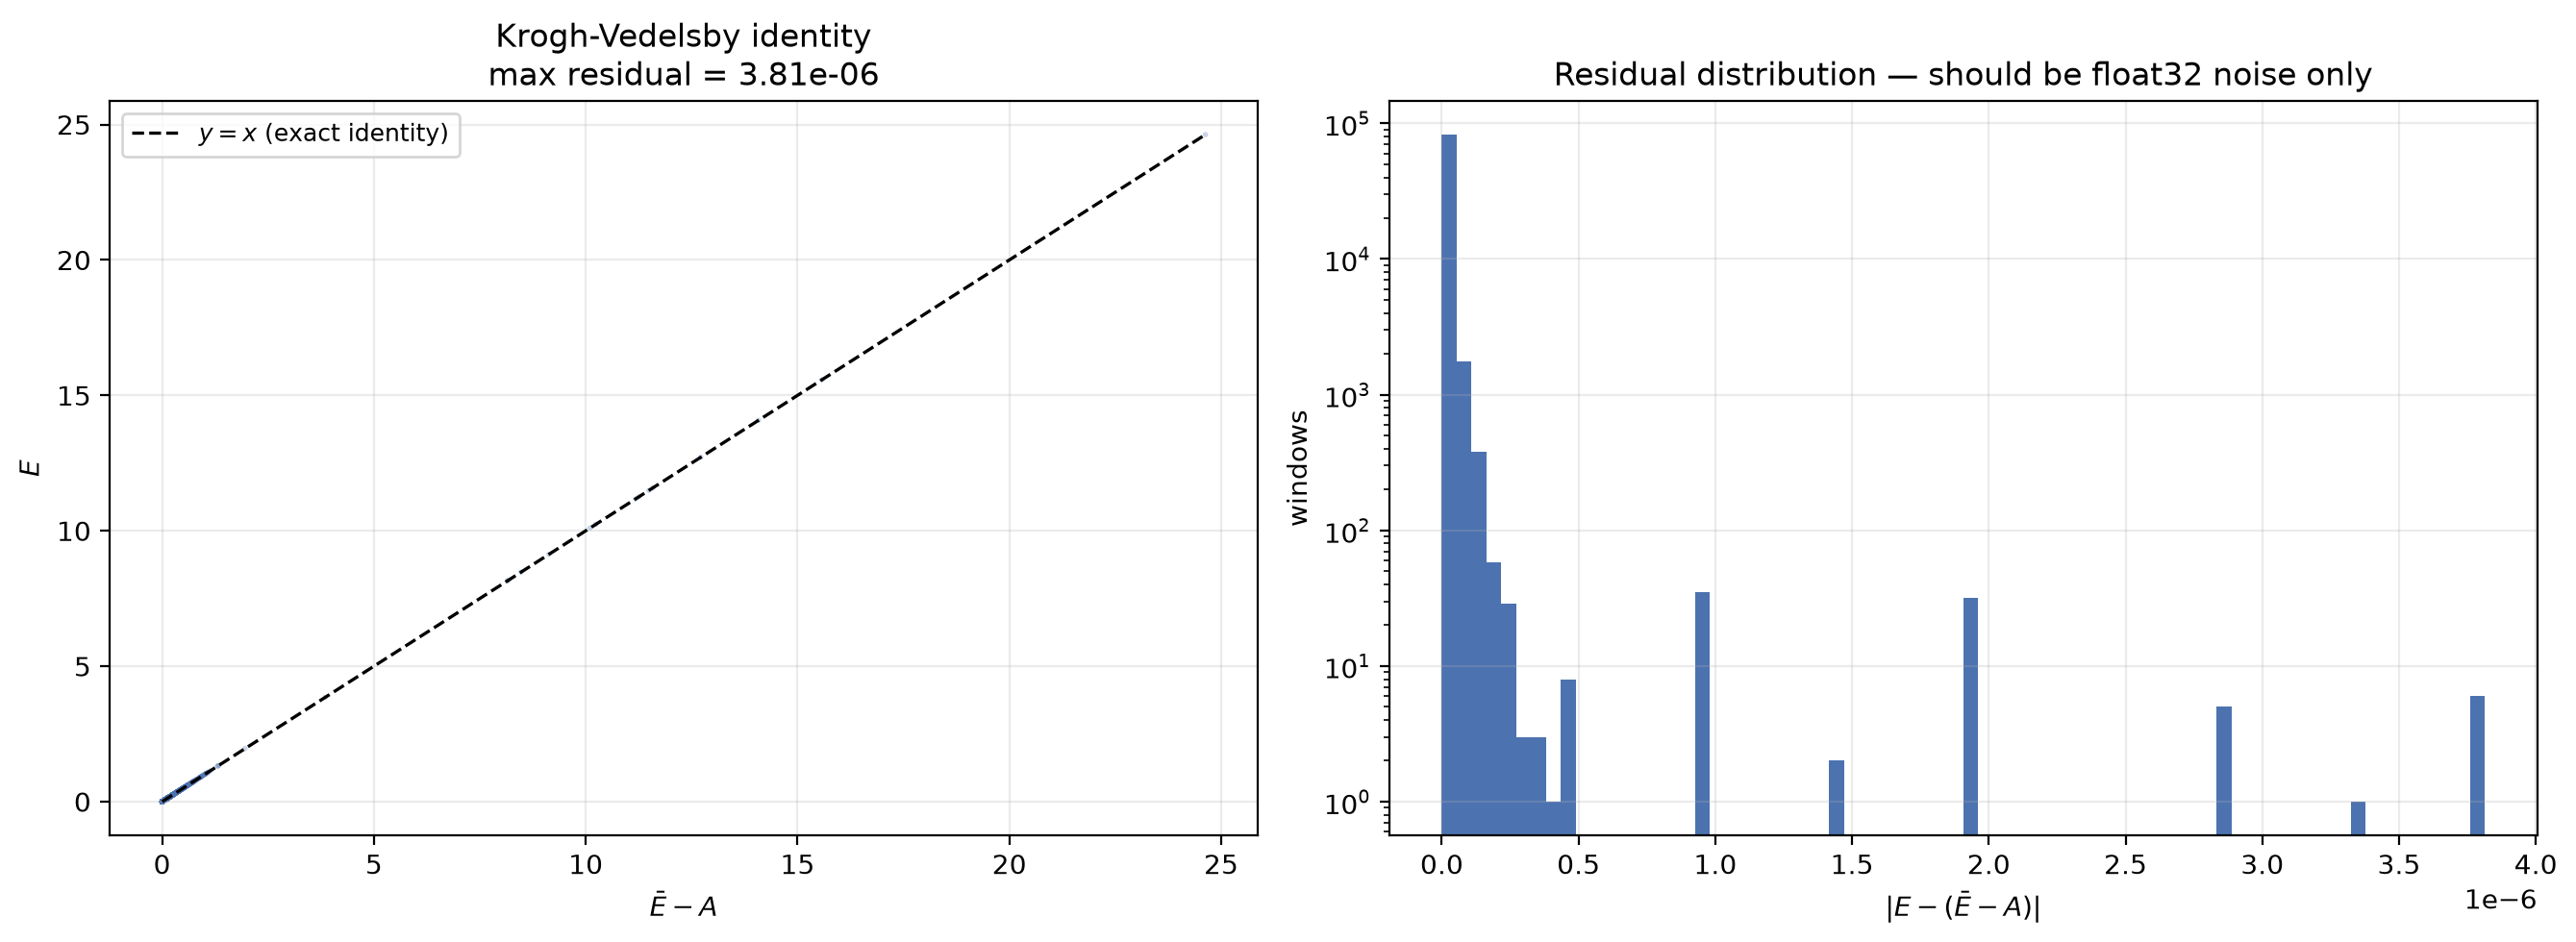

**kv_quadrants.png** — Low disagreement/high error shows why agreement alone cannot certify reliability.

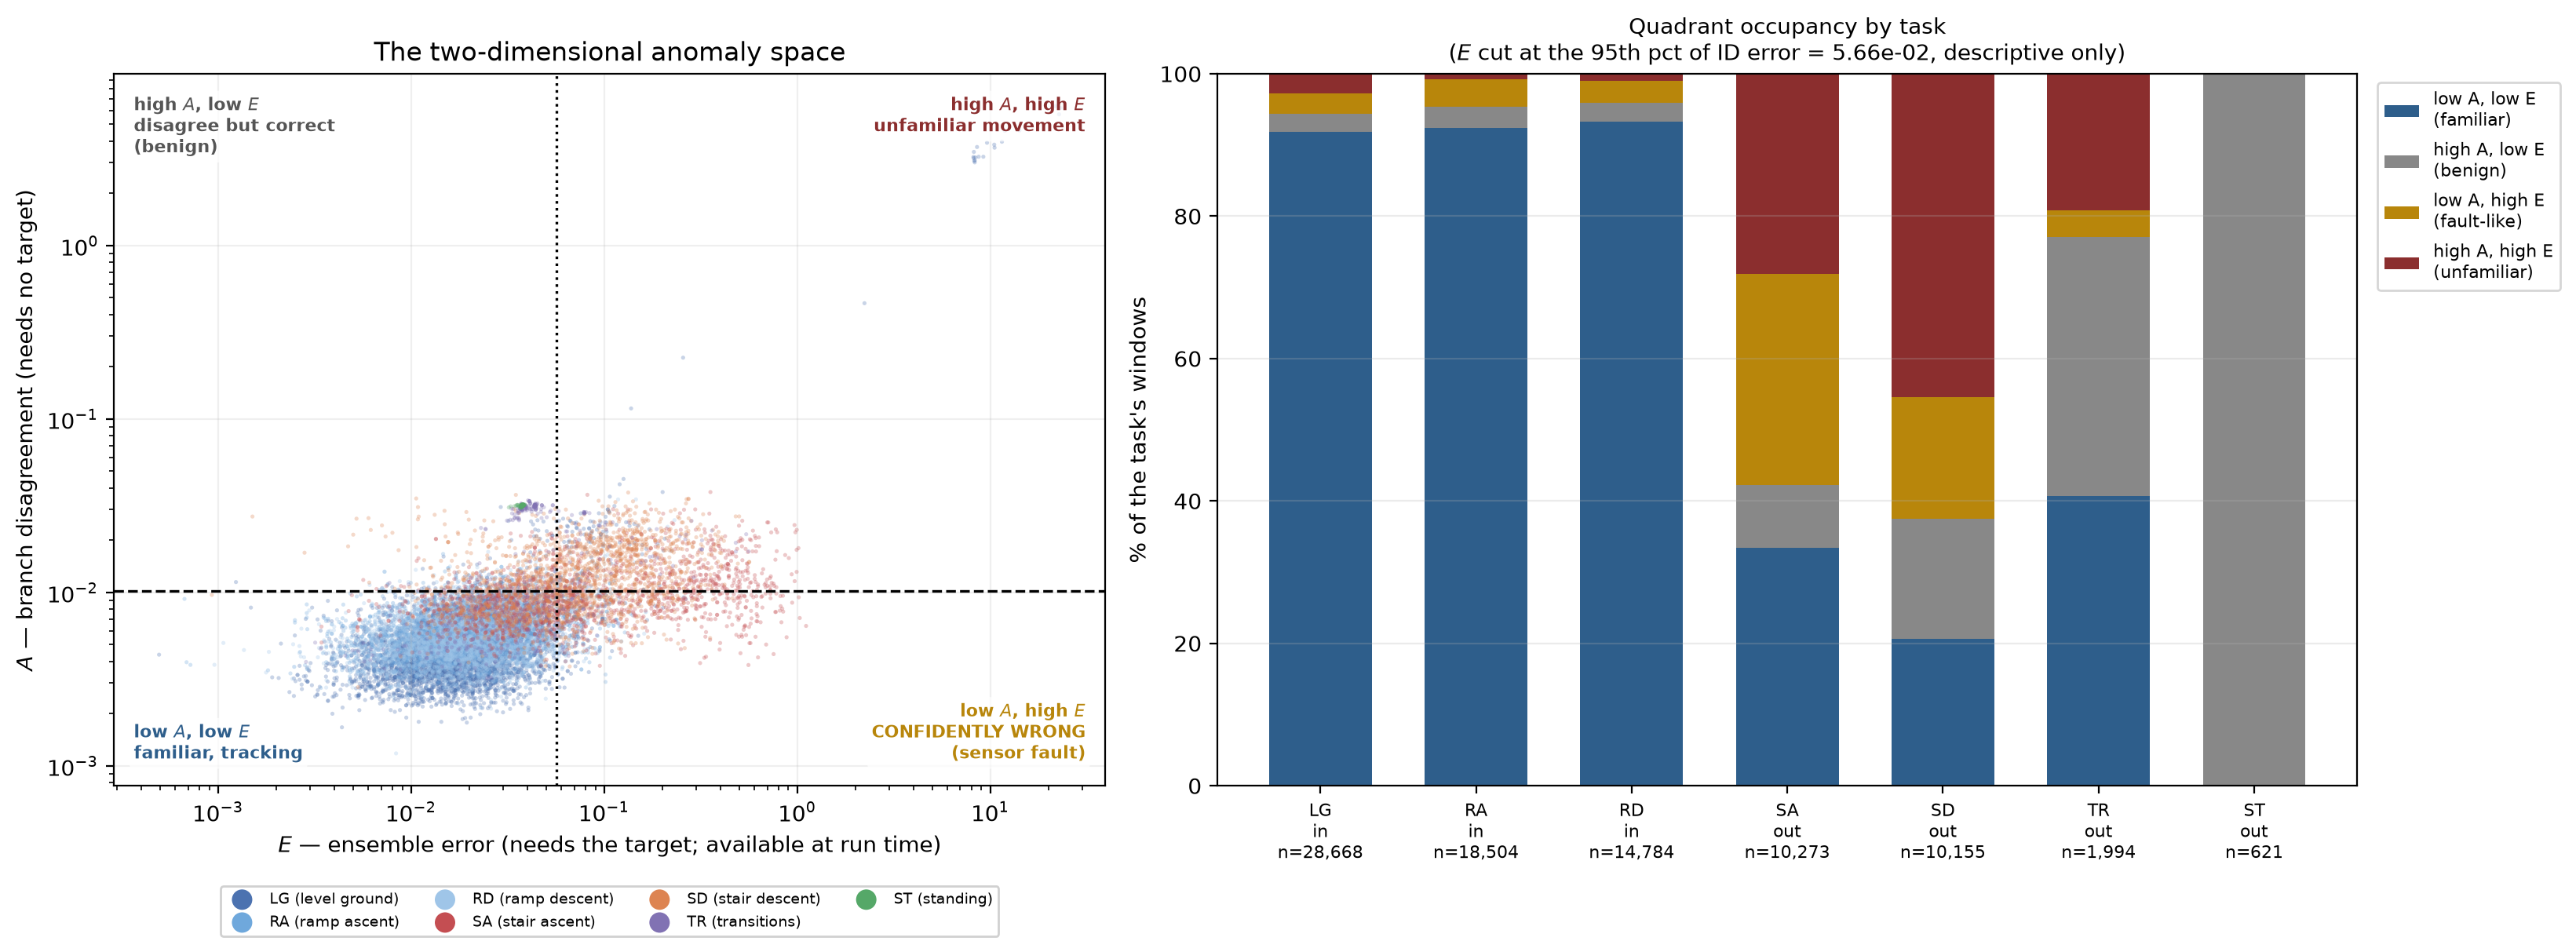

**kv_roc_compare.png** — Error-based diagnostics versus disagreement. Do not confuse the failed ratio with error alone.

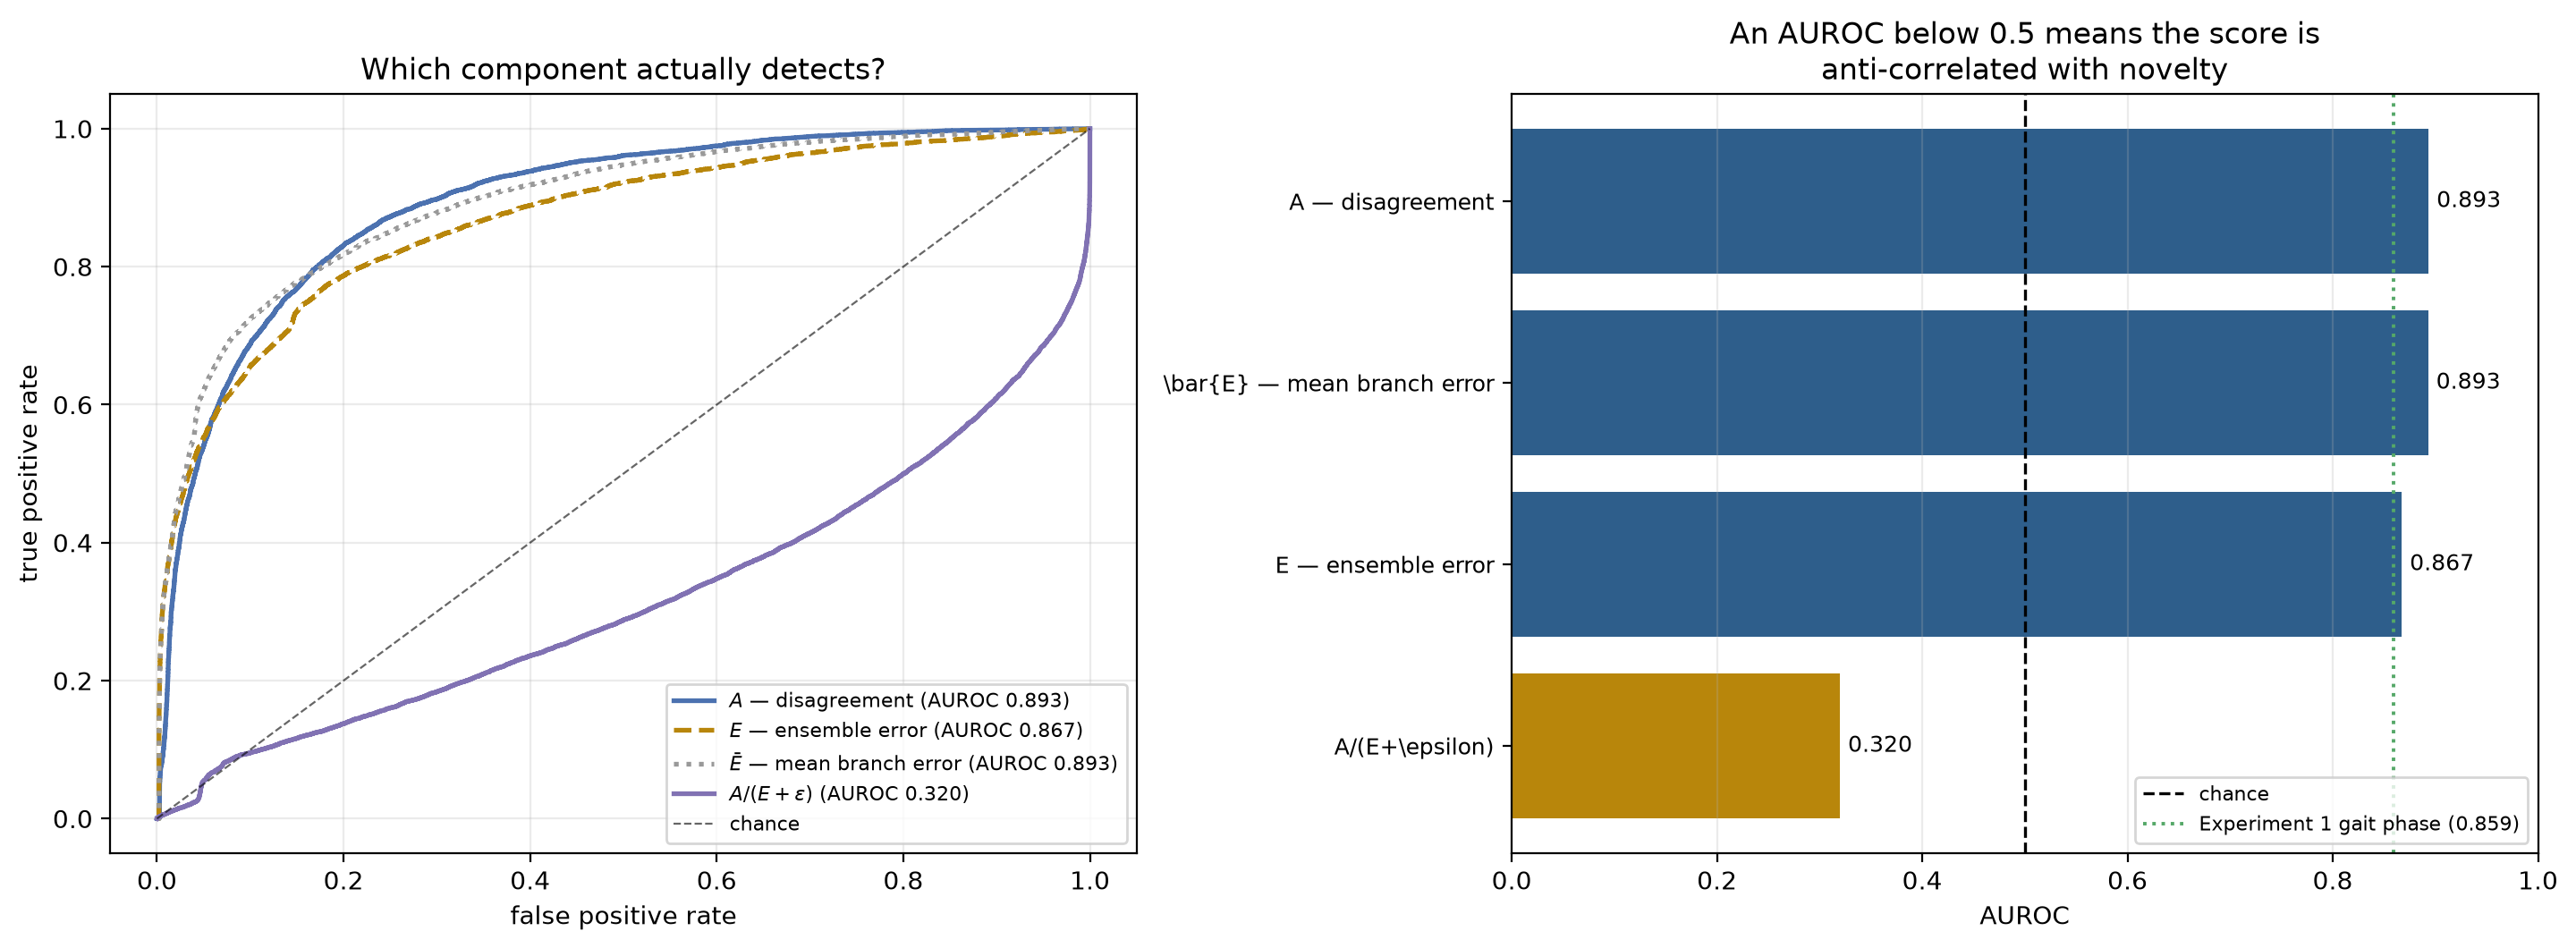

In [9]:
gallery(RUN, [('psi_by_task.png', 'Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.'), ('roc.png', 'Threshold sweep: ranking quality, not the fraction detected at the saved threshold.'), ('detection_by_task.png', 'Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.'), ('kv_identity.png', 'Numerical check of E = mean branch error − disagreement, on compatible unfiltered quantities.'), ('kv_quadrants.png', 'Low disagreement/high error shows why agreement alone cannot certify reliability.'), ('kv_roc_compare.png', 'Error-based diagnostics versus disagreement. Do not confuse the failed ratio with error alone.')])

## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,primary,0.8274,13.4819,3.6734,0.0981,10273
1,ST,primary,0.3200,0.0000,3.2212,-0.0322,621
2,TR,primary,0.6489,3.9619,2.4444,0.0152,1994


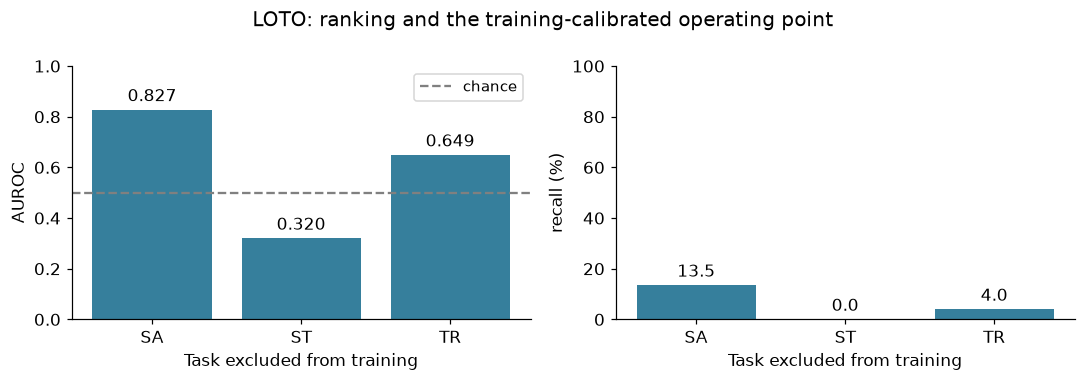

In [10]:
loto_results(KEY)

## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

### Held out: SA — stair ascent

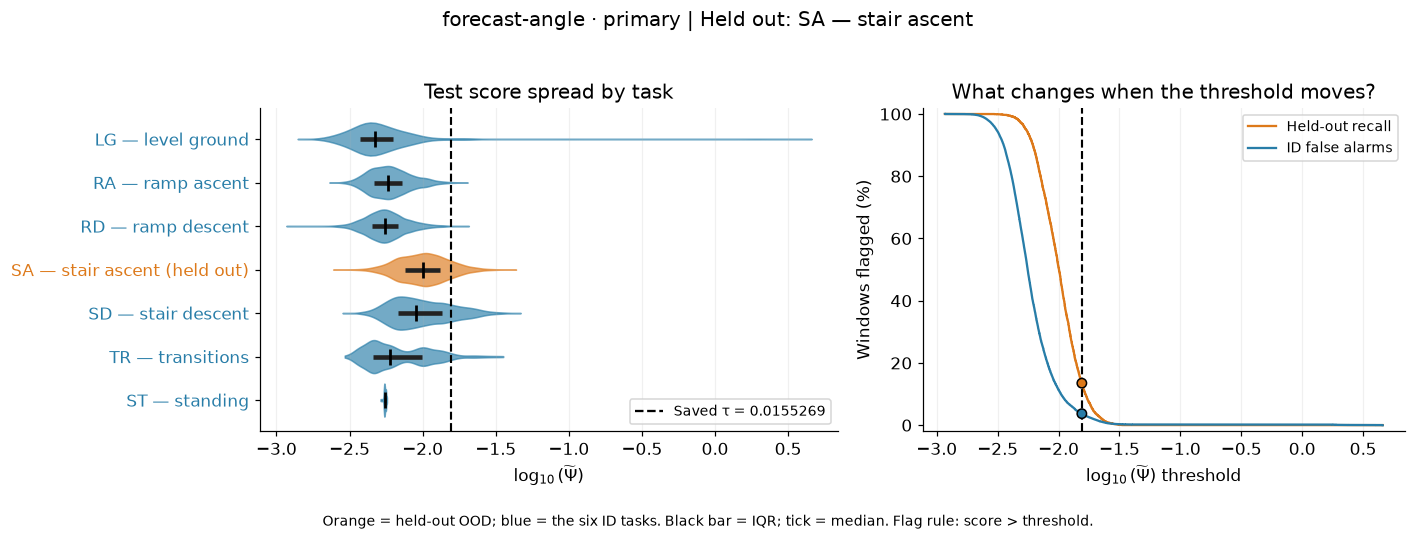

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.0077634393,73.19,22.31
1,,0.011645159,35.14,7.53
2,,0.013974191,19.94,4.76
3,,0.014750535,16.33,4.13
4,,0.01537161,13.93,3.76
5,saved,0.015526879,13.48,3.67
6,,0.015682147,12.84,3.57
7,,0.016303223,10.84,3.21
8,,0.017079567,8.80,2.83
9,,0.019408598,4.53,1.95


**Per-task flags at τ = 0.015526879** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,2.52
1,RA,ID,18504,0.34
2,RD,ID,14784,0.29
3,SA,held-out OOD,10273,13.48
4,SD,ID,10155,17.77
5,TR,ID,1994,5.57
6,ST,ID,621,0.00


### Held out: ST — standing

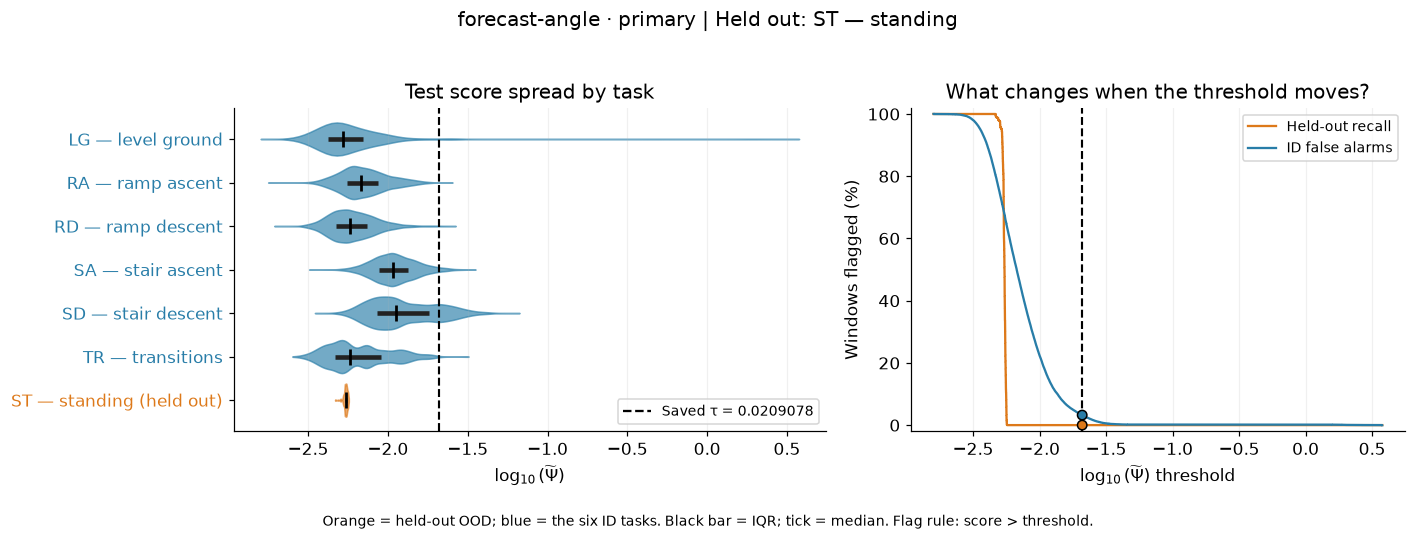

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.010453915,0.00,20.10
1,,0.015680873,0.00,6.82
2,,0.018817047,0.00,4.31
3,,0.019862439,0.00,3.75
4,,0.020698752,0.00,3.32
5,saved,0.02090783,0.00,3.22
6,,0.021116909,0.00,3.12
7,,0.021953222,0.00,2.75
8,,0.022998613,0.00,2.35
9,,0.026134788,0.00,1.37


**Per-task flags at τ = 0.02090783** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.91
1,RA,ID,18504,0.02
2,RD,ID,14784,0.32
3,SA,ID,10273,2.99
4,SD,ID,10155,17.75
5,TR,ID,1994,0.50
6,ST,held-out OOD,621,0.00


### Held out: TR — transitions

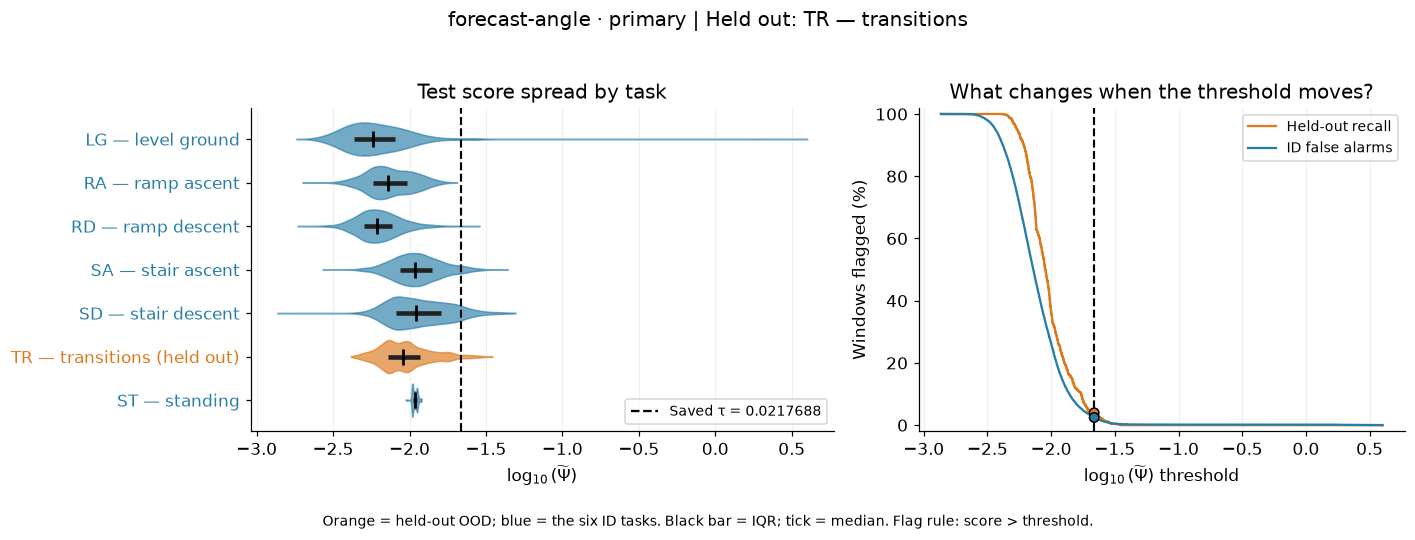

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.01088442,29.39,20.72
1,,0.01632663,11.13,6.15
2,,0.019591956,4.71,3.60
3,,0.020680398,4.21,3.02
4,,0.021551152,4.06,2.55
5,saved,0.02176884,3.96,2.44
6,,0.021986528,3.51,2.35
7,,0.022857282,3.06,1.99
8,,0.023945724,2.71,1.67
9,,0.02721105,1.20,0.95


**Per-task flags at τ = 0.02176884** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.98
1,RA,ID,18504,0.00
2,RD,ID,14784,0.16
3,SA,ID,10273,4.73
4,SD,ID,10155,9.37
5,TR,held-out OOD,1994,3.96
6,ST,ID,621,0.00


In [11]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
LOTO_SCORE = 'primary'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

## Takeaway and next checks

Strong original-protocol ranking and useful live targets, but standing/transition LOTO expose limits of task-novelty detection. An unseen task can be easy to predict; evaluate task novelty and actual forecast failure separately.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [12]:
source_links(['ml/sci_rob/vanilla/targets.py', 'ml/sci_rob/vanilla/training/synthetic.py', 'ml/sci_rob/vanilla/evaluation/ambiguity.py'])

Implementation sources: [targets.py](../../../ml/sci_rob/vanilla/targets.py), [synthetic.py](../../../ml/sci_rob/vanilla/training/synthetic.py), [ambiguity.py](../../../ml/sci_rob/vanilla/evaluation/ambiguity.py)